In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## win-rate

**Figure 3: Human preference evaluation, comparing LIMA to 5 different baselines across 300 test prompts.** Crowd workers prefer LIMA's response over Alpaca 65B on 53% of prompts and over DaVinci003 on 44%; against BARD, Claude and GPT-4, LIMA's response is equal or better on 58%, 46% and 43% of prompts.

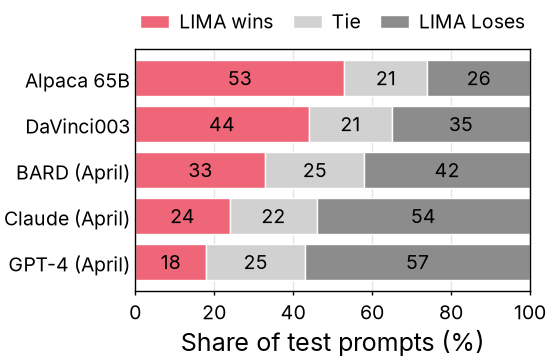

In [2]:
with open("../data/win-rate.json") as f:
    data = json.load(f)
opponents = data["opponents"]
category_colors = {
    "LIMA wins": colors["ours"],
    "Tie": lighten(colors["neutral"]),
    "LIMA Loses": colors["neutral"],
}

fig, ax = plt.subplots(figsize=(2.75, 2))
y = np.arange(len(opponents))
left = np.zeros(len(opponents))
for category in data["categories"]:
    color = category_colors[category]
    bars = ax.barh(y, data[category], left=left, color=color, edgecolor="white", linewidth=0.5, label=category)
    ax.bar_label(bars, fmt="%d", label_type="center", color=text_color(color))
    left += data[category]

ax.set_yticks(y, labels=opponents)
ax.invert_yaxis()
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of test prompts (%)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=0.5, ncol=3, frameon=False)

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/win-rate.pdf")
fig.savefig("../outputs/win-rate.png")
plt.show()